# 1) Importação de Bibliotecas

In [1]:
import json
import pandas as pd
import numpy as np
import seaborn as sns
from scipy.stats import randint

from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_score, cross_val_predict, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)


pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

In [2]:
root = Path.cwd()
meta_data_dir = root.parent
data_dir = root.parent / "model" / "data"

# 2) SetUp de Dados

In [3]:
train = pd.read_csv(data_dir / "train.csv")
test = pd.read_csv(data_dir / "test.csv")
metadata = json.loads((meta_data_dir / "model" / "metadata.json").read_text())

target_column = metadata['target']

x_train = train.drop(columns=[target_column], axis=1)
y_train = train[target_column]
x_test = test.drop(columns=[target_column], axis=1)
y_test = test[target_column]

class_order = metadata["classes"]
print(f"Train: {x_train.shape}  |  Test: {x_test.shape}")
print(f"Classes ({len(class_order)}): {class_order}")
print(f"Distribuição no train:\n{y_train.value_counts()}")

Train: (14609, 81)  |  Test: (3653, 81)
Classes (12): ['ARP_poisioning', 'DDOS_Slowloris', 'DOS_SYN_Hping', 'MQTT_Publish', 'Metasploit_Brute_Force_SSH', 'NMAP_FIN_SCAN', 'NMAP_OS_DETECTION', 'NMAP_TCP_scan', 'NMAP_UDP_SCAN', 'NMAP_XMAS_TREE_SCAN', 'Thing_Speak', 'Wipro_bulb']
Distribuição no train:
Attack_type
Thing_Speak                   6073
ARP_poisioning                4232
MQTT_Publish                  3313
DDOS_Slowloris                 425
Wipro_bulb                     175
NMAP_UDP_SCAN                  154
NMAP_XMAS_TREE_SCAN             64
NMAP_OS_DETECTION               60
DOS_SYN_Hping                   46
NMAP_TCP_scan                   35
Metasploit_Brute_Force_SSH      28
NMAP_FIN_SCAN                    4
Name: count, dtype: int64


# 3) Treinamento dos modelos

In [4]:
# Definição das camadas de teste
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Modelo de Aprendizagem de Máquina
rf_model = RandomForestClassifier(n_estimators=400, class_weight="balanced_subsample", random_state=42)

In [5]:
scoring_params = [
    "accuracy", "balanced_accuracy", "f1_macro", "f1_weighted"
]

df_scores = cross_validate(rf_model, X=x_train, y=y_train, cv=cv, scoring=scoring_params)

for score in scoring_params:
    metric = df_scores[f'test_{score}']
    print(f'{score}: {metric.mean()} | {metric.std()}')

accuracy: 0.9780958722921094 | 0.001904889940587191
balanced_accuracy: 0.8413365388970288 | 0.021145426611189694
f1_macro: 0.8561498516295383 | 0.014468963812217652
f1_weighted: 0.9777594966260802 | 0.0021080816428315657


In [6]:
# Fine Tunning de Hiper-Parâmetros

params = {
    "n_estimators":      randint(100, 800),
    "max_depth":         [10, 15, 20, 25, 30, 35, 40, None],
    "min_samples_leaf":  [1, 3, 5, 10],
    "min_samples_split": [2, 5, 10],
    "max_features":      ["sqrt", "log2", 0.3],
    "class_weight":      ["balanced", "balanced_subsample"],
}

rf_estimator = RandomForestClassifier(n_jobs=-1, random_state=42)

search = RandomizedSearchCV(estimator=rf_estimator,
                            param_distributions=params, 
                            n_iter=50, 
                            cv=cv, 
                            scoring="f1_macro", 
                            random_state=42, 
                            verbose=1)

search.fit(x_train, y_train)
best_option = search.best_estimator_

print(f'Melhores Parâmetros: {search.best_params_}')
print(f'Melhor f1-macro: {search.best_score_}')

Fitting 3 folds for each of 50 candidates, totalling 150 fits


KeyboardInterrupt: 

Classification Report:                             precision    recall  f1-score   support

            ARP_poisioning       0.98      1.00      0.99      1058
            DDOS_Slowloris       0.91      0.90      0.90       107
             DOS_SYN_Hping       1.00      1.00      1.00        11
              MQTT_Publish       1.00      1.00      1.00       828
Metasploit_Brute_Force_SSH       0.83      0.71      0.77         7
             NMAP_FIN_SCAN       0.00      0.00      0.00         1
         NMAP_OS_DETECTION       1.00      1.00      1.00        15
             NMAP_TCP_scan       1.00      1.00      1.00         9
             NMAP_UDP_SCAN       0.65      0.63      0.64        38
       NMAP_XMAS_TREE_SCAN       1.00      0.81      0.90        16
               Thing_Speak       1.00      0.99      0.99      1519
                Wipro_bulb       0.91      0.91      0.91        44

                  accuracy                           0.98      3653
                 macro 

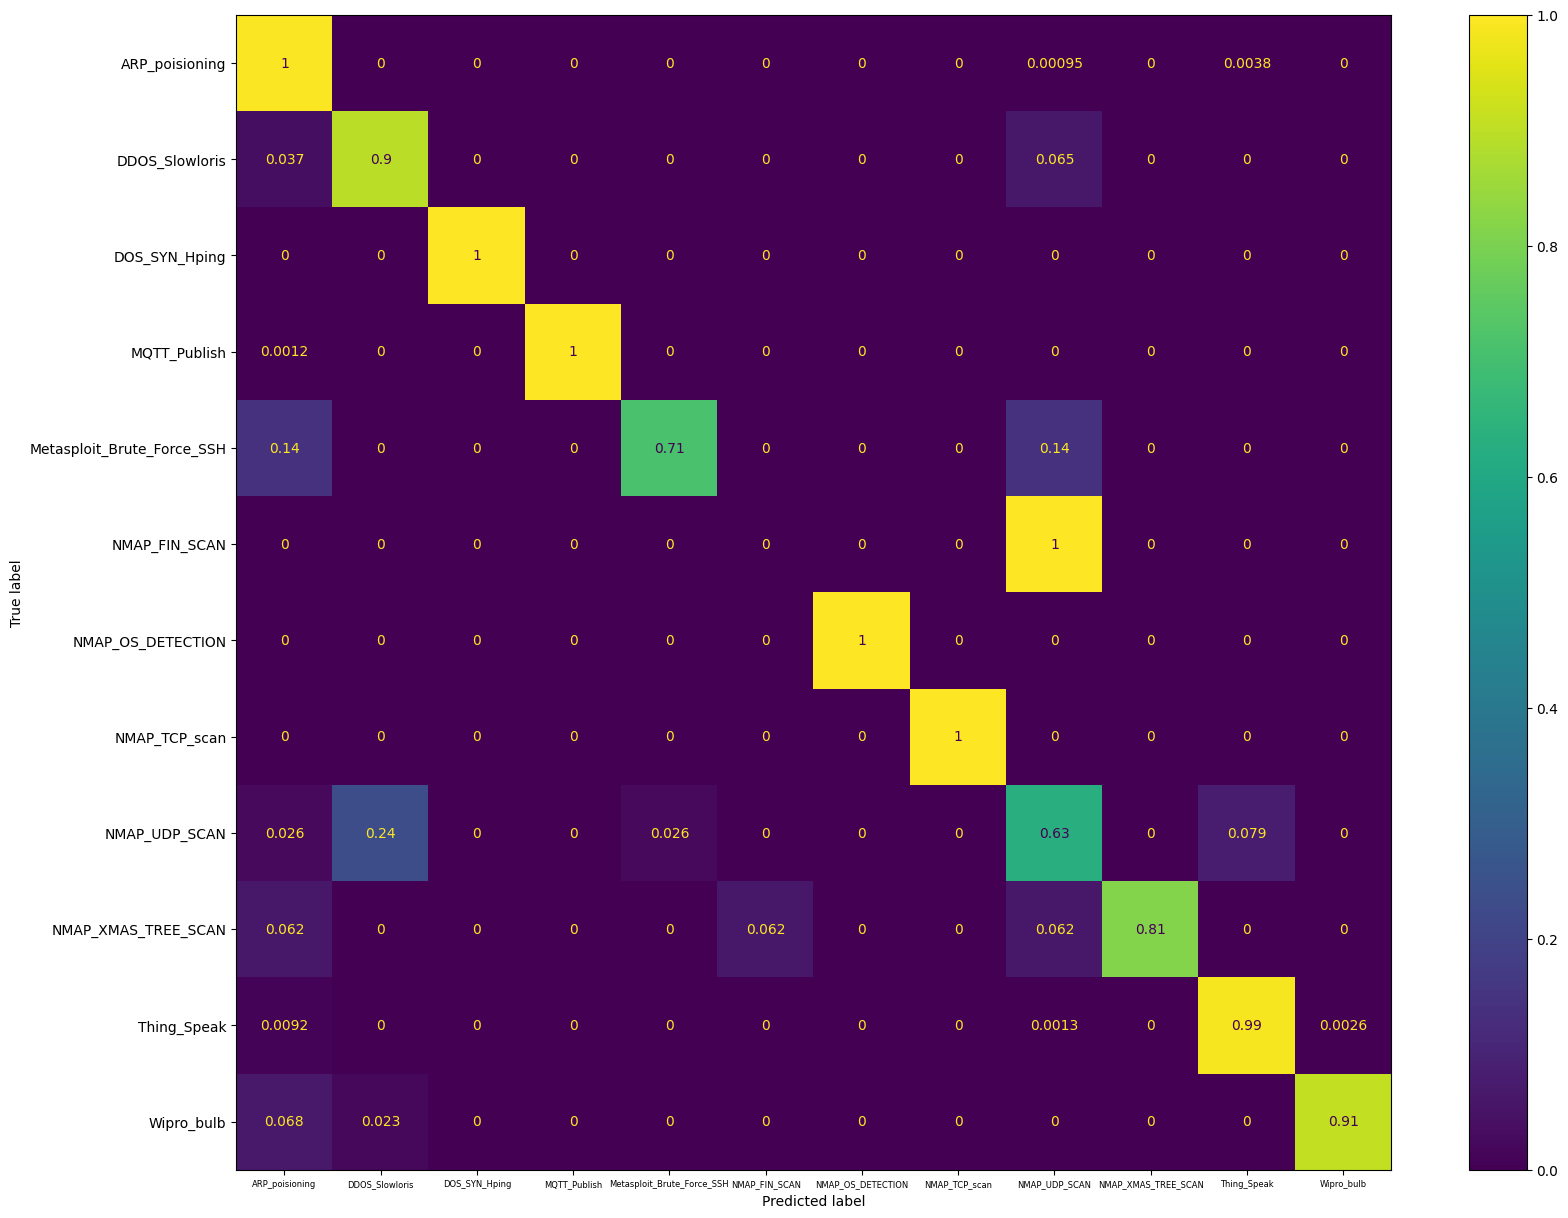

: 

In [ ]:
# Avaliação final de teste
y_test_pred = best_option.predict(x_test)

cr = classification_report(y_test, y_test_pred, zero_division=0)

print('F1-Macro: ', f1_score(y_test, y_test_pred, average="macro"))
print('F1-Weighted: ', f1_score(y_test, y_test_pred, average="weighted"))
print('Accuracy Score: ', accuracy_score(y_test, y_test_pred))
print('Balanced Accuracy Score: ', balanced_accuracy_score(y_test, y_test_pred), "\n")

print(cr)

In [ ]:
# Matriz de Confusão

cm = confusion_matrix(y_test, y_test_pred, normalize="true")

fig, ax  =plt.subplots(1,1, figsize=(20,15))
ax.tick_params(axis='x', labelsize=6)

cmd = ConfusionMatrixDisplay(cm, display_labels=best_option.classes_)
cmd.plot(ax=ax, values_format=".2f", xticks_rotation=45)
plt.show()